# Pertemuan 11 — Tugas 2: Klasifikasi Siang dan Malam dengan Fitur Histogram (SVM RBF)

Tugas ini mengklasifikasikan citra **day** dan **night** (dataset Praktikum 5) menggunakan SVM kernel RBF dengan **fitur histogram warna**. Data dipecah 80:20 dan dilakukan *hyperparameter tuning* pada kernel RBF.

Sumber: [Tugas Praktikum](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2/tugas-praktikum).

## 1. Import Library

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 2. Load Data

Seluruh citra (training dan test) dari dataset Praktikum 5 digabungkan beserta labelnya (day = 1, night = 0).

In [2]:
def load_all_images(base='images'):
    X_raw = []
    y_raw = []
    for split in ['training', 'test']:
        for folder, label_val in [('day', 1), ('night', 0)]:
            for p in (Path(base) / split / folder).glob('*.jpg'):
                img = cv2.imread(str(p))
                if img is not None:
                    X_raw.append(img)
                    y_raw.append(label_val)
    return X_raw, np.array(y_raw)

X_raw, y = load_all_images()
print('Jumlah citra:', len(X_raw))
print('Distribusi label:', dict(zip(*np.unique(y, return_counts=True))))

Jumlah citra: 400
Distribusi label: {np.int64(0): np.int64(200), np.int64(1): np.int64(200)}


## 3. Ekstraksi Fitur Histogram Warna

Setiap citra diubah ke ruang warna HSV, lalu dihitung histogram 3D (H, S, V) dengan 8 bin per kanal dan dinormalisasi. Hasilnya menjadi vektor fitur sepanjang 8 x 8 x 8 = 512.

In [3]:
def color_histogram(img, bins=8):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None,
                        [bins, bins, bins], [0, 180, 0, 256, 0, 256])
    hist = cv2.normalize(hist, hist).flatten()
    return hist

X = np.array([color_histogram(img) for img in X_raw])
print('Shape X:', X.shape)
print('Shape y:', y.shape)

Shape X: (400, 512)
Shape y: (400,)


## 4. Split Data 80:20

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Ukuran data latih:', X_train.shape)
print('Ukuran data uji:', X_test.shape)

Ukuran data latih: (320, 512)
Ukuran data uji: (80, 512)


## 5. Tuning Hyperparameter kernel RBF

GridSearchCV mencoba kombinasi `C` dan `gamma` untuk mendapatkan hyperparameter terbaik dengan cross-validation 5-fold.

In [5]:
pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))

param_grid = {'svc__C': [0.1, 1, 10, 100],
              'svc__gamma': [0.001, 0.01, 0.1, 1]}

grid = GridSearchCV(pipe, param_grid, cv=5)
grid.fit(X_train, y_train)

print('Best params:', grid.best_params_)
print('Best CV score:', grid.best_score_)

Best params: {'svc__C': 10, 'svc__gamma': 0.001}
Best CV score: 0.975


## 6. Evaluasi Model Terbaik

Model terbaik digunakan untuk memprediksi data latih dan uji, lalu diukur akurasi, classification report, dan confusion matrix.

In [6]:
model = grid.best_estimator_

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print('Accuracy train:', accuracy_score(y_train, y_train_pred))
print('Accuracy test :', accuracy_score(y_test, y_test_pred))
print()
print(classification_report(y_test, y_test_pred, target_names=['night', 'day']))

Accuracy train: 1.0
Accuracy test : 0.9875

              precision    recall  f1-score   support

       night       0.98      1.00      0.99        40
         day       1.00      0.97      0.99        40

    accuracy                           0.99        80
   macro avg       0.99      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



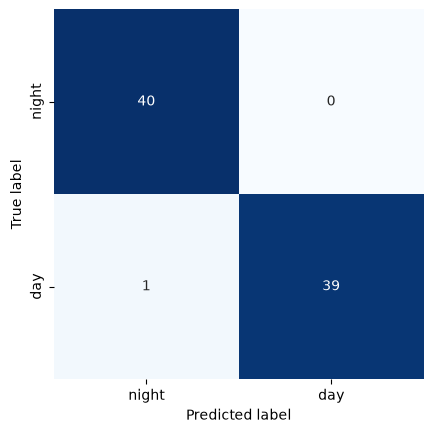

In [7]:
import seaborn as sns

mat = confusion_matrix(y_test, y_test_pred)
sns.heatmap(mat, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=['night', 'day'], yticklabels=['night', 'day'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()